# 04 · USF-MAE: ultrasound foundation model adaptation
**OMARI Seminar Series — From Pixels to Predictions: Developing AI Models for Medical Image Interpretation**

Retrieve and verify the official 100-epoch USF-MAE checkpoint, transfer its ViT-B/16 encoder into a classifier, demonstrate masked reconstruction (if decoder weights are present), fine-tune on FETAL_PLANES_DB, and export embeddings. USF-MAE is **not** pretrained here.

| | |
|---|---|
| **Runtime** | GPU recommended: demo ≈15 min, full ≈1–2 h per regime |
| **Needs** | Google Drive access for the checkpoint (gdown); `splits/split_manifest.csv` |
| **Produces** | `checkpoints/usf_mae_100ep.pth`, `runs/usf_mae_*`, `usf_mae_test_embeddings.npz` |
| **Modes** | `smoke` (synthetic data, random weights: checks the code only) · `demo` (real data subset, few epochs) · `full` (complete experiment) |

> Results from `smoke` mode are meaningless by construction and must never be exported to the website.
> Every artifact written by these notebooks records the script, checkpoint hash and parameters that produced it.

In [ ]:
#@title 0 · Setup: repository, packages, data and artifact folders { display-mode: "form" }
import os, sys, subprocess, json, random, time
MODE = "full"  #@param ["smoke", "demo", "full"]
REPO_URL = "https://github.com/Dick-AI-Lab/omari-workshop.git"  #@param {type:"string"}
DATA_ROOT = "/content/data/FETAL_PLANES_ZENODO"  #@param {type:"string"}
ARTIFACTS = "/content/omari_artifacts"  #@param {type:"string"}
USE_DRIVE_FOR_ARTIFACTS = True  #@param {type:"boolean"}
MODE = os.environ.get("OMARI_MODE", MODE)            # lets CI / nbclient override
ARTIFACTS = os.environ.get("OMARI_ARTIFACTS", ARTIFACTS)
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB and USE_DRIVE_FOR_ARTIFACTS:
    from google.colab import drive
    drive.mount("/content/drive")
    ARTIFACTS = "/content/drive/MyDrive/omari_artifacts"

# 1) make `omari_us` importable: installed package > local checkout (../python) > clone REPO_URL
def _find_repo():
    for cand in [os.getcwd(), os.path.dirname(os.getcwd()), "/content/omari-workshop"]:
        if os.path.isdir(os.path.join(cand, "python", "omari_us")):
            return cand
    return None
REPO = _find_repo()
if REPO is None:
    if "YOUR-ORG" in REPO_URL:
        raise RuntimeError("Set REPO_URL to the repository that contains python/omari_us (or upload the repo to /content/omari-workshop).")
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/omari-workshop"], check=True)
    REPO = "/content/omari-workshop"
sys.path.insert(0, os.path.join(REPO, "python"))

# 2) packages (Colab already has torch/torchvision; timm and friends are added)
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm>=0.9.12", "scikit-learn", "scipy", "pyyaml", "opencv-python-headless", "gdown"], check=True)

import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
import omari_us
from omari_us.utils import seed_everything, get_device, CLASSES, CLASS_SHORT
SEED = 42
seed_everything(SEED)
DEVICE = get_device()
os.makedirs(ARTIFACTS, exist_ok=True)
SPLITS_CSV = os.path.join(ARTIFACTS, "splits", "split_manifest.csv")
RUNS = os.path.join(ARTIFACTS, "runs")
print(f"omari_us {omari_us.__version__} | torch {torch.__version__} | device {DEVICE} | MODE={MODE} | artifacts → {ARTIFACTS}")
if DEVICE.type == "cpu" and MODE != "smoke":
    print("⚠ No GPU. In Colab: Runtime → Change runtime type → T4 GPU. CPU training of these models is impractically slow.")

Mounted at /content/drive
omari_us 0.1.0 | torch 2.14.1+cu130 | device cuda | MODE=full | artifacts → /content/drive/MyDrive/omari_artifacts


In [ ]:
#@title 1 · Data: download FETAL_PLANES_DB (2.1 GB, CC BY 4.0) or build the synthetic smoke dataset { display-mode: "form" }
from omari_us.datasets import read_metadata, make_splits, synthetic_metadata, save_split_manifest, load_split_manifest, ZENODO_URL, ZENODO_MD5

def ensure_fetal_planes(root=DATA_ROOT):
    """Download + verify + extract the Zenodo archive if the metadata CSV is not already present."""
    import glob, hashlib
    if glob.glob(os.path.join(root, "**", "FETAL_PLANES_DB_data.csv"), recursive=True):
        return
    os.makedirs(root, exist_ok=True)
    z = os.path.join(os.path.dirname(root), "FETAL_PLANES_ZENODO.zip")
    if not os.path.exists(z):
        print("downloading", ZENODO_URL)
        subprocess.run(["curl", "-L", "--fail", "-o", z, ZENODO_URL], check=True)
    md5 = hashlib.md5(open(z, "rb").read()).hexdigest()
    assert md5 == ZENODO_MD5, f"md5 mismatch: {md5}"
    subprocess.run(["unzip", "-q", "-n", z, "-d", root], check=True)

if MODE == "smoke":
    SMOKE_DIR = os.path.join(ARTIFACTS, "smoke_data")
    meta = synthetic_metadata(60, (2, 5), seed=0, image_dir=os.path.join(SMOKE_DIR, "Images"), size=(200, 150))
    print("SMOKE MODE: synthetic grey images; every number below is meaningless.")
else:
    ensure_fetal_planes()
    meta = read_metadata(DATA_ROOT)
print(meta.shape)
meta.head()

downloading https://zenodo.org/records/3904280/files/FETAL_PLANES_ZENODO.zip?download=1
(12400, 9)


,Image_name,Patient_num,Plane,Brain_plane,Operator,US_Machine,Train,label,path
0,Patient00001_Plane1_1_of_15,1,Other,Not A Brain,Other,Aloka,1,5,/content/data/FETAL_PLANES_ZENODO/Images/Patie...
1,Patient00001_Plane1_2_of_15,1,Other,Not A Brain,Other,Aloka,1,5,/content/data/FETAL_PLANES_ZENODO/Images/Patie...
2,Patient00001_Plane1_3_of_15,1,Other,Not A Brain,Other,Aloka,1,5,/content/data/FETAL_PLANES_ZENODO/Images/Patie...
3,Patient00001_Plane1_4_of_15,1,Other,Not A Brain,Other,Aloka,1,5,/content/data/FETAL_PLANES_ZENODO/Images/Patie...
4,Patient00001_Plane1_5_of_15,1,Other,Not A Brain,Other,Aloka,1,5,/content/data/FETAL_PLANES_ZENODO/Images/Patie...


In [ ]:
# Load the split manifest written by notebook 01 (or rebuild it identically from the metadata)
if os.path.exists(SPLITS_CSV) and MODE != "smoke":
    splits = load_split_manifest(SPLITS_CSV, DATA_ROOT)
else:
    splits = make_splits(meta, val_fraction=0.15 if MODE == "smoke" else 0.1, seed=SEED)
    save_split_manifest(splits, SPLITS_CSV)
if MODE == "demo":  # stratified patient subset for speed
    keep = splits.groupby("split", group_keys=False).apply(lambda d: d[d.Patient_num.isin(pd.Series(d.Patient_num.unique()).sample(frac=0.25, random_state=SEED))])
    splits = keep.reset_index(drop=True)
print(splits.groupby(["split"]).agg(images=("Image_name", "size"), patients=("Patient_num", "nunique")))

       images  patients
split                  
test     5271       896
train    6425       809
val       704        87


## 1 · Retrieve the checkpoint
Source: https://github.com/Yusufii9/USF-MAE (README → Checkpoints → *USF-MAE (100 epochs – recommended)*; Google Drive id `1ZPu_7KhMEuaq-XdLhVp2EEgMgLJ4dKhr`).
In `smoke` mode a randomly initialised MAE checkpoint in the same format is created instead.

In [ ]:
CKPT = os.path.join(ARTIFACTS, "checkpoints", "usf_mae_500ep.pth")
os.makedirs(os.path.dirname(CKPT), exist_ok=True)
from omari_us.models.usf_mae import USF_MAE_500EP_GDRIVE_ID, mae_vit_base_patch16_dec512d8b
if MODE == "smoke":
    torch.save({"model": mae_vit_base_patch16_dec512d8b().state_dict()}, CKPT)
elif not os.path.exists(CKPT):
    import gdown
    gdown.download(id=USF_MAE_500EP_GDRIVE_ID, output=CKPT, quiet=False)
print(CKPT, f"{os.path.getsize(CKPT)/1e6:.0f} MB")

Downloading...
From (original): https://drive.google.com/uc?id=15n71qHXSBjEjrLtCOzvBb6gTsGhh7NUg
From (redirected): https://drive.google.com/uc?id=15n71qHXSBjEjrLtCOzvBb6gTsGhh7NUg&confirm=t&uuid=9ff9721d-52a5-4439-af9a-0ca31be80c68
To: /content/drive/MyDrive/omari_artifacts/checkpoints/usf_mae_500ep.pth
100%|██████████| 448M/448M [00:10<00:00, 43.4MB/s]

/content/drive/MyDrive/omari_artifacts/checkpoints/usf_mae_500ep.pth 448 MB


## 2 · Verify compatibility
`load_usf_mae_checkpoint` strips `module.`/`model.` prefixes, compares every tensor with `mae_vit_base_patch16_dec512d8b`, checks the positional embedding equals MAE's fixed sin-cos table, and reports whether decoder weights exist.

In [ ]:
from omari_us.models.usf_mae import load_usf_mae_checkpoint
sd, report = load_usf_mae_checkpoint(CKPT)
print(report.summary())
assert report.ok_for_classification, "encoder unusable"

checkpoint: /content/drive/MyDrive/omari_artifacts/checkpoints/usf_mae_500ep.pth
sha256: c659a06170b0f6967ae7f6d066681b8dea2c122a5f325bb8a82df11ffb3a2533
container keys: ['cls_token', 'pos_embed', 'mask_token', 'decoder_pos_embed', 'patch_embed.proj.weight', 'patch_embed.proj.bias', 'blocks.0.norm1.weight', 'blocks.0.norm1.bias', 'blocks.0.attn.qkv.weight', 'blocks.0.attn.qkv.bias', 'blocks.0.attn.proj.weight', 'blocks.0.attn.proj.bias', 'blocks.0.norm2.weight', 'blocks.0.norm2.bias', 'blocks.0.mlp.fc1.weight', 'blocks.0.mlp.fc1.bias', 'blocks.0.mlp.fc2.weight', 'blocks.0.mlp.fc2.bias', 'blocks.1.norm1.weight', 'blocks.1.norm1.bias', 'blocks.1.attn.qkv.weight', 'blocks.1.attn.qkv.bias', 'blocks.1.attn.proj.weight', 'blocks.1.attn.proj.bias', 'blocks.1.norm2.weight', 'blocks.1.norm2.bias', 'blocks.1.mlp.fc1.weight', 'blocks.1.mlp.fc1.bias', 'blocks.1.mlp.fc2.weight', 'blocks.1.mlp.fc2.bias', 'blocks.2.norm1.weight', 'blocks.2.norm1.bias', 'blocks.2.attn.qkv.weight', 'blocks.2.attn.qkv.b

## 3 · Masked reconstruction (requires decoder weights)
Identical preprocessing to the official loader: `Resize((224,224), NEAREST)`, ImageNet mean/std. The loss is MSE on masked patches of normalised
pixels (`norm_pix_loss=False`). Images shown are de-normalised and averaged over channels.

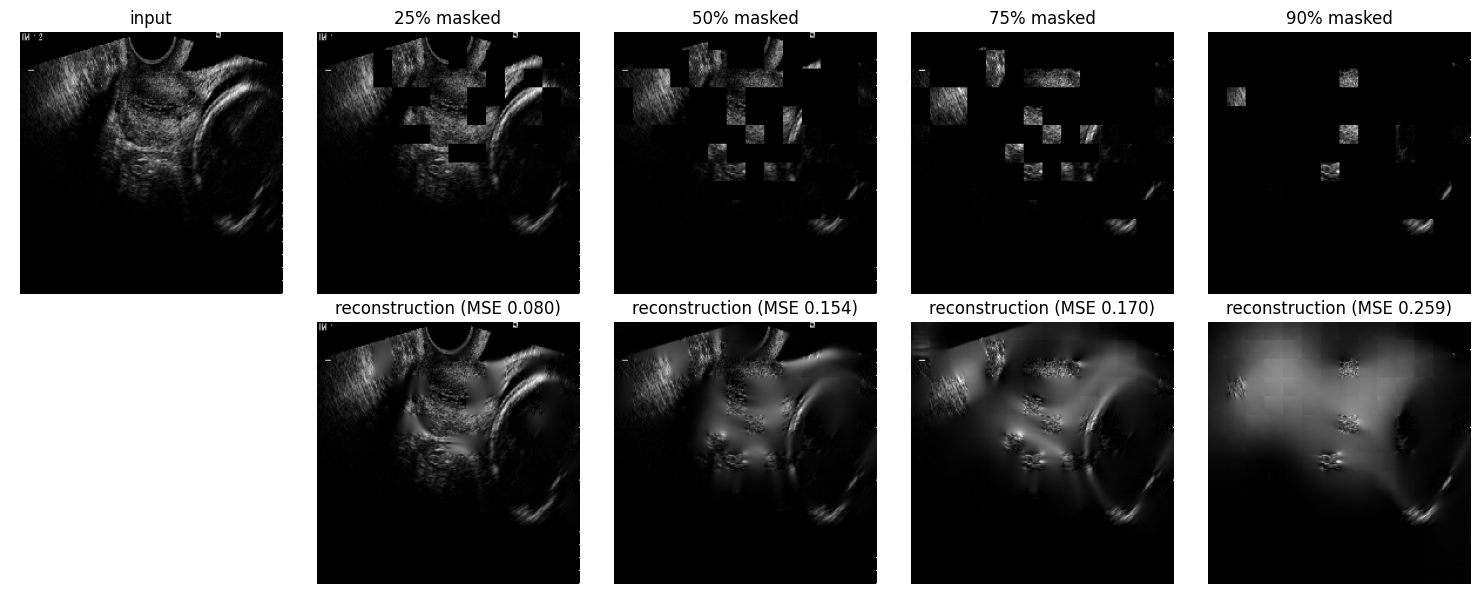

In [ ]:
from omari_us.models.usf_mae import build_mae_from_state_dict, reconstruct
from omari_us.datasets import input_spec, build_transforms, denormalize
from PIL import Image
spec = input_spec("usf_mae"); tf = build_transforms(spec, False)
if report.ok_for_reconstruction:
    mae = build_mae_from_state_dict(sd).to(DEVICE)
    row = splits[splits.split == "test"].iloc[0]
    x = tf(Image.open(row.path).convert("L")).unsqueeze(0).to(DEVICE)
    ratios = [0.25, 0.5, 0.75, 0.9]
    fig, axes = plt.subplots(2, len(ratios) + 1, figsize=(15, 6))
    axes[0, 0].imshow(denormalize(x[0], spec).cpu(), cmap="gray"); axes[0, 0].set_title("input"); axes[1, 0].axis("off")
    for k, r in enumerate(ratios, 1):
        out = reconstruct(mae, x, r, seed=0)
        m = out["mask"][0].reshape(14, 14).repeat_interleave(16, 0).repeat_interleave(16, 1).cpu()
        axes[0, k].imshow(denormalize(x[0], spec).cpu() * (1 - m), cmap="gray"); axes[0, k].set_title(f"{int(r*100)}% masked")
        axes[1, k].imshow(denormalize(out["pasted"][0], spec).cpu(), cmap="gray"); axes[1, k].set_title(f"reconstruction (MSE {out['loss']:.3f})")
    for a in axes.flat: a.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Decoder weights absent: no reconstruction is shown (nothing is synthesised in its place).")

## 4 · Dataset overlap (must be reported)
FETAL_PLANES_DB is dataset 25 of OpenUS-46, the USF-MAE pretraining corpus. Its images, **without labels**, were therefore seen during
self-supervised pretraining, possibly including our test images. This is a transductive advantage over the ImageNet-initialised baselines.
Report it with every USF-MAE result on this dataset. A clean test needs a USF-MAE variant pretrained without FETAL_PLANES_DB, or an external fetal test set.
The public pretraining notebook also initialises from Facebook's ImageNet MAE checkpoint (`mae_pretrain_vit_base_full.pth`), so USF-MAE = ImageNet MAE → ultrasound MAE.

## Train: frozen encoder (linear probe) and full fine-tuning
Both regimes use the same patient-disjoint splits, class-weighted cross-entropy with label smoothing, cosine schedule with warm-up,
and model selection by **validation macro-F1**. The test split is evaluated once with the selected checkpoint.
Hyper-parameters come from `configs/usf_mae.yaml`; `demo` shortens epochs, `smoke` uses random weights and 2 batches.

In [ ]:
from omari_us.training import TrainConfig, train
from omari_us.utils import load_yaml
C = load_yaml(os.path.join(REPO, "configs", "usf_mae.yaml"))
def make_cfg(regime, label_fraction=1.0, seed=0):
    r = dict(C["regimes"][regime])
    cfg = TrainConfig(model="usf_mae", regime=regime, label_fraction=label_fraction, seed=seed, out_dir=RUNS,
                      loss=C["loss"], weight_scheme=C["weight_scheme"], label_smoothing=C["label_smoothing"], patience=C["patience"],
                      input_overrides=C.get("input", {}), augment=C.get("augment", {}), usf_mae_checkpoint=CKPT, usf_mae_global_pool=C.get("global_pool", "token"), **r)
    if MODE == "demo":
        cfg.epochs = min(cfg.epochs, 4)
    if MODE == "smoke":
        cfg.epochs, cfg.batch_size, cfg.max_train_batches, cfg.max_eval_batches = 2, 4, 2, 2
        cfg.pretrained, cfg.num_workers, cfg.amp = False, 0, False
    return cfg

results = {}
for regime in ["frozen", "finetune"]:
    t0 = time.time()
    results[regime] = train(make_cfg(regime), splits)
    s = results[regime]
    print(f"{regime:9s} best epoch {s['best_epoch']} | val macro-F1 {s['best_val_macro_f1']:.3f} | test macro-F1 {s['test']['macro_f1']:.3f} | {time.time()-t0:.0f}s")

usf_mae_frozen_lf1_s0:   0%|          | 0/15 [00:00<?, ?it/s]

/content/omari-workshop/python/omari_us/training/__init__.py:202: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  tot += float(loss) * len(y)


frozen    best epoch 13 | val macro-F1 0.806 | test macro-F1 0.804 | 644s


usf_mae_finetune_lf1_s0:   0%|          | 0/25 [00:00<?, ?it/s]

finetune  best epoch 9 | val macro-F1 0.954 | test macro-F1 0.940 | 642s


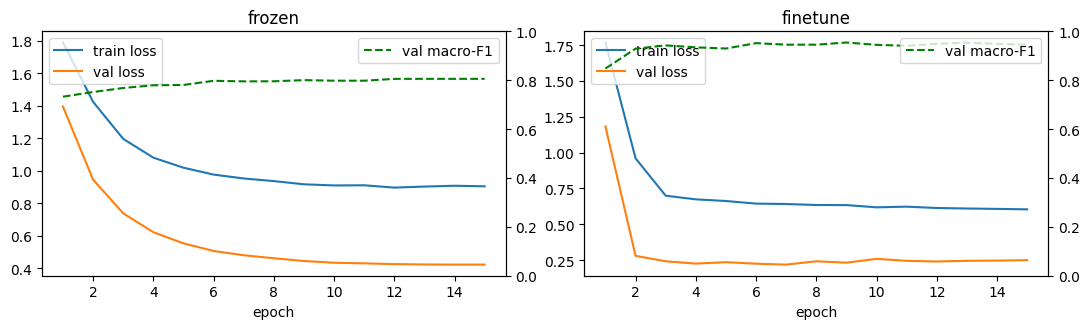

In [ ]:
# Learning curves (written to history.json in each run folder)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, regime in zip(axes, ["frozen", "finetune"]):
    h = json.load(open(os.path.join(RUNS, results[regime]["run"], "history.json")))
    ax.plot(h["epoch"], h["train_loss"], label="train loss"); ax.plot(h["epoch"], h["val_loss"], label="val loss")
    ax2 = ax.twinx(); ax2.plot(h["epoch"], h["val_macro_f1"], "g--", label="val macro-F1"); ax2.set_ylim(0, 1)
    ax.set_title(regime); ax.set_xlabel("epoch"); ax.legend(loc="upper left"); ax2.legend(loc="upper right")
plt.tight_layout(); plt.show()

In [ ]:
from omari_us.evaluation import classification_report
z = np.load(os.path.join(RUNS, results["finetune"]["run"], "test_predictions.npz"), allow_pickle=True)
rep = classification_report(z["labels"], z["probs"].argmax(1))
print(f"test accuracy {rep['accuracy']:.3f} | macro-F1 {rep['macro_f1']:.3f} | balanced accuracy {rep['balanced_accuracy']:.3f}")
pd.DataFrame(rep["per_class"], index=CLASS_SHORT).round(3)

test accuracy 0.946 | macro-F1 0.940 | balanced accuracy 0.953


,precision,recall,f1,support
Abdomen,0.849,0.972,0.906,358
Brain,0.989,0.995,0.992,1472
Femur,0.857,0.924,0.889,524
Thorax,0.956,0.948,0.952,660
Cervix,0.985,0.997,0.991,645
Other,0.944,0.882,0.912,1612


### Optional: label-efficiency sweep
Repeats training on patient-level label fractions (1–100%) × seeds. Expensive in `full` mode (18 runs per regime);
notebook 05 collects the `summary.json` files into the website's learning-curve figure.

In [ ]:
RUN_LABEL_SWEEP = True  #@param {type:"boolean"}
SWEEP_REGIME = "finetune"  #@param ["frozen", "finetune"]
if RUN_LABEL_SWEEP:
    fracs = C["label_fractions"] if MODE == "full" else [0.05, 0.25, 1.0]
    seeds = C["seeds"] if MODE == "full" else [0]
    for f in fracs:
        for s in seeds:
            r = train(make_cfg(SWEEP_REGIME, f, s), splits, progress=False)
            print(r["run"], round(r["test"]["macro_f1"], 4))

usf_mae_finetune_lf0.01_s0 0.6146
usf_mae_finetune_lf0.01_s1 0.6726
usf_mae_finetune_lf0.01_s2 0.623
usf_mae_finetune_lf0.05_s0 0.8916
usf_mae_finetune_lf0.05_s1 0.8938
usf_mae_finetune_lf0.05_s2 0.879
usf_mae_finetune_lf0.1_s0 0.9074
usf_mae_finetune_lf0.1_s1 0.8831
usf_mae_finetune_lf0.1_s2 0.911
usf_mae_finetune_lf0.25_s0 0.9237
usf_mae_finetune_lf0.25_s1 0.9318
usf_mae_finetune_lf0.25_s2 0.9339
usf_mae_finetune_lf0.5_s0 0.9384
usf_mae_finetune_lf0.5_s1 0.9296
usf_mae_finetune_lf0.5_s2 0.9375
usf_mae_finetune_lf1_s0 0.9403
usf_mae_finetune_lf1_s1 0.9402
usf_mae_finetune_lf1_s2 0.9443


## 5 · Embeddings for the test set
[CLS] features of the fine-tuned encoder, saved for notebook 05 and visualised with PCA.

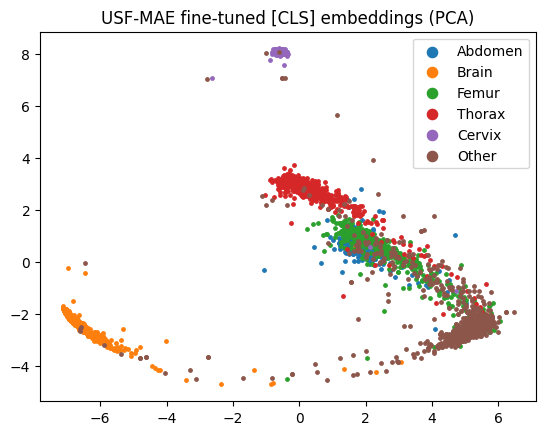

In [ ]:
from omari_us.models import load_finetuned
from omari_us.datasets import FetalPlanesDataset
from torch.utils.data import DataLoader
ft, _ = load_finetuned("usf_mae", os.path.join(RUNS, results["finetune"]["run"], "best.pt"))
ft = ft.to(DEVICE).eval()
te = splits[splits.split == "test"]
if MODE != "full": te = te.sample(min(600, len(te)), random_state=SEED)
dl = DataLoader(FetalPlanesDataset(te, tf), batch_size=64)
feats, labs = [], []
with torch.no_grad():
    for x, y, _ in dl:
        feats.append(ft.forward_head(ft.forward_features(x.to(DEVICE)), pre_logits=True).cpu()); labs.append(y)
F_, Y = torch.cat(feats).numpy(), torch.cat(labs).numpy()
np.savez_compressed(os.path.join(ARTIFACTS, "usf_mae_test_embeddings.npz"), features=F_, labels=Y, ids=te.Image_name.to_numpy())
from sklearn.decomposition import PCA
Z = PCA(2, random_state=SEED).fit_transform(F_)
for c in range(6): plt.scatter(*Z[Y == c].T, s=6, label=CLASS_SHORT[c])
plt.legend(markerscale=3); plt.title("USF-MAE fine-tuned [CLS] embeddings (PCA)"); plt.show()

## References
- Burgos-Artizzu X.P. et al. *Evaluation of deep convolutional neural networks for automatic classification of common maternal fetal ultrasound planes.* Sci. Rep. 10, 10200 (2020). Dataset: Zenodo 3904280, CC BY 4.0.
- Huang G. et al. *Densely connected convolutional networks.* CVPR 2017.
- Dosovitskiy A. et al. *An image is worth 16×16 words.* ICLR 2021; Steiner A. et al. *How to train your ViT?* TMLR 2022.
- He K. et al. *Masked autoencoders are scalable vision learners.* CVPR 2022.
- Megahed Y. et al. *USF-MAE: Ultrasound self-supervised foundation model with masked autoencoding.* Biomed. Signal Process. Control 122, 110313 (2026). https://github.com/Yusufii9/USF-MAE
- Zhou B. et al. CAM, CVPR 2016 · Selvaraju R.R. et al. Grad-CAM, ICCV 2017 · Chattopadhay A. et al. Grad-CAM++, WACV 2018 · Abnar & Zuidema, attention rollout, ACL 2020 · Chefer H. et al., CVPR 2021 · Adebayo J. et al., sanity checks, NeurIPS 2018 · Petsiuk V. et al., RISE / deletion–insertion, BMVC 2018 · Guo C. et al., calibration, ICML 2017.